# Experiment readout: guided onboarding checklist

**Question:** should Product ship the new guided setup checklist (treatment) to all new signups, replacing the current onboarding (control)?

**Data note:** Tasklane is a fictional company and the data is simulated, including the treatment assignment. The workflow is what a real readout would look like. Run `python python/generate_data.py` then `python python/run_pipeline.py` before this notebook.

**Contents**
1. Pre-registered design: hypothesis, metrics, decision rule, sample size
2. Trust checks: sample ratio mismatch, covariate balance, exclusions
3. Primary result: activation
4. Secondary metrics and guardrails
5. Robustness: covariate-adjusted estimate
6. Who benefits, and does the effect fade? (exploratory)
7. Power and what the test could not tell us
8. Business impact
9. Decision

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep, proportion_effectsize
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.rates import confint_poisson_2indep
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT / "python"))
import style
style.apply()

df = pd.read_csv(ROOT / "outputs" / "exp_users_export.csv", parse_dates=["signup_date"])
df["is_treat"] = (df.variant == "treatment").astype(int)
df["invited_48h"] = (df.hours_to_invite <= 48).astype(int)   # NaN (never invited) counts as 0
df["mrr_30d"] = df.mrr_usd * df.paid_30d
c, t = df[df.variant == "control"], df[df.variant == "treatment"]
R = {}   # results carried into the memo
print(f"{len(df):,} users | control {len(c):,} | treatment {len(t):,} | signups {df.signup_date.min().date()} to {df.signup_date.max().date()}")

17,770 users | control 8,797 | treatment 8,973 | signups 2025-10-13 to 2025-11-23


## 1. Pre-registered design

These were fixed before looking at outcomes.

| Item | Decision |
|---|---|
| **Hypothesis** | A guided setup checklist that prompts users to create a project and invite a teammate raises the share of new signups who activate within 7 days |
| **Unit and assignment** | New signup, randomised 50/50 at signup, 100% of traffic |
| **Primary metric** | 7-day activation rate (first project **and** a teammate invited within 7 days of signup) |
| **Secondary metrics** | Paid conversion within 30 days; invited a teammate within 48 hours; active in week 2 |
| **Guardrails** | Support tickets per user in first 14 days (must not rise more than 10%); week-2 activity (must not fall more than 1 point) |
| **Test** | Two-sided two-proportion z-test, alpha = 0.05; Newcombe 95% intervals; Holm correction across the 3 secondary metrics |
| **Minimum detectable effect (MDE)** | +2.5 points absolute on activation |
| **Practical significance bar** | A lift must be credibly above +1.0 point to justify shipping and maintaining the feature (assumption, see section 8) |
| **Analysis rule** | Fixed horizon. No early stopping on interim results |
| **Decision rule** | Ship if the primary criteria are met and no guardrail is breached. A criterion is *Met* when the confidence bound clears its threshold, *Inconclusive* when the point estimate is fine but the interval crosses the threshold, and *Not met* otherwise |

In [2]:
ALPHA, POWER = 0.05, 0.80
trend = pd.read_csv(ROOT / "outputs" / "funnel_monthly_trend.csv", parse_dates=["signup_month"])
baseline = trend[trend.signup_month.between("2025-08-01", "2025-10-01")].activated_pct.mean() / 100   # pre-test baseline
MDE = 0.025
h = proportion_effectsize(baseline + MDE, baseline)
n_arm = int(np.ceil(NormalIndPower().solve_power(effect_size=h, alpha=ALPHA, power=POWER, ratio=1)))
daily = pd.read_csv(ROOT / "outputs" / "exp_daily_enrolment.csv").groupby("signup_date").users.sum()
days_needed = int(np.ceil(2 * n_arm / daily.mean()))

# paid conversion planning: what would it take to see a +1 point lift?
base_paid = c.paid_30d.mean()
n_arm_paid = int(np.ceil(NormalIndPower().solve_power(effect_size=proportion_effectsize(base_paid + 0.01, base_paid), alpha=ALPHA, power=POWER)))

print(f"Pre-test activation baseline (Aug-Oct 2025): {baseline:.1%}")
print(f"Users per arm for 80% power to detect +{MDE*100:.1f} pts on activation: {n_arm:,}")
print(f"At {daily.mean():,.0f} signups/day and 100% of traffic that takes about {days_needed} days; the test ran 42 days")
print(f"For comparison, detecting +1.0 pt on 30-day paid conversion (baseline {base_paid:.1%}) needs {n_arm_paid:,} users per arm")
R.update(baseline=baseline, mde=MDE, n_arm_required=n_arm, days_required=days_needed, n_arm_required_paid_1pt=n_arm_paid)

Pre-test activation baseline (Aug-Oct 2025): 33.2%
Users per arm for 80% power to detect +2.5 pts on activation: 5,668
At 423 signups/day and 100% of traffic that takes about 27 days; the test ran 42 days
For comparison, detecting +1.0 pt on 30-day paid conversion (baseline 11.4%) needs 16,494 users per arm


**Why 42 days when the activation test needs fewer?** Two business cycles is the minimum to cover weekday and weekend behaviour, the 30-day paid metric needs follow-up time anyway, and a longer window lets us see whether the effect fades after the novelty of a new screen wears off. It does not change the activation answer; we did not stop early.

## 2. Trust checks

In [3]:
wf = pd.read_csv(ROOT / "outputs" / "exp_population_waterfall.csv")
display(wf.rename(columns={"description": "Population step", "users": "Users"}).drop(columns="step").style.format({"Users": "{:,}"}).hide(axis="index"))

# Sample ratio mismatch: is the split consistent with a fair 50/50 coin?
obs = np.array([len(c), len(t)])
chi, p_srm = stats.chisquare(obs, f_exp=[obs.sum() / 2] * 2)
print(f"Sample ratio check: control {obs[0]:,} vs treatment {obs[1]:,}  (treatment share {obs[1]/obs.sum():.2%}), chi-square p = {p_srm:.3f}")
print("Rule: investigate if p < 0.001. ", "PASS" if p_srm >= 0.001 else "FAIL")

# Covariate balance: did randomisation produce comparable groups?
rows = []
for col in ["acquisition_channel", "device", "company_size", "test_week"]:
    ct = pd.crosstab(df[col], df.variant)
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    rows.append({"Covariate": col, "Chi-square p-value": round(p, 3)})
display(pd.DataFrame(rows).style.hide(axis="index"))
R.update(srm_p=p_srm, n_control=len(c), n_treatment=len(t))

Population step,Users
Assignment rows in raw table,"18,053"
Distinct users assigned,"17,981"
Less: users shown both arms,-72
Less: internal test accounts (conflict-free),-139
Analysis population,"17,770"


Sample ratio check: control 8,797 vs treatment 8,973  (treatment share 50.50%), chi-square p = 0.187
Rule: investigate if p < 0.001.  PASS


Covariate,Chi-square p-value
acquisition_channel,0.386000
device,0.696000
company_size,0.291000
test_week,0.426000


Neither check raises a flag. The 72 users who were shown both arms (cookie loss) were removed rather than guessed at; at 0.4% of assignments they cannot move the result, but leaving them in would blur the treatment definition.

## 3. Primary result: 7-day activation

In [4]:
def two_prop(d, col):
    xc, nc, xt, nt = c[col].sum(), len(c), t[col].sum(), len(t)
    z, p = proportions_ztest([xt, xc], [nt, nc])
    lo, hi = confint_proportions_2indep(xt, nt, xc, nc, method="newcomb", compare="diff")
    rlo, rhi = confint_proportions_2indep(xt, nt, xc, nc, method="score", compare="ratio")
    pc, pt = xc / nc, xt / nt
    return dict(metric=col, control=pc, treatment=pt, diff=pt - pc, ci_lo=lo, ci_hi=hi, rel=pt / pc - 1, rel_lo=rlo - 1, rel_hi=rhi - 1, z=z, p=p)

prim = two_prop(df, "activated")
print(f"Control {prim['control']:.2%}  |  Treatment {prim['treatment']:.2%}")
print(f"Absolute lift {prim['diff']*100:+.2f} pts  (95% CI {prim['ci_lo']*100:+.2f} to {prim['ci_hi']*100:+.2f})")
print(f"Relative lift {prim['rel']:+.1%}  (95% CI {prim['rel_lo']:+.1%} to {prim['rel_hi']:+.1%})")
print(f"z = {prim['z']:.2f}, two-sided p = {prim['p']:.2g}")

# cross-check with a bootstrap (resample both arms)
rng = np.random.default_rng(7)
B = 20000
bs = rng.binomial(len(t), t.activated.mean(), B) / len(t) - rng.binomial(len(c), c.activated.mean(), B) / len(c)
print(f"Bootstrap 95% interval: {np.percentile(bs, 2.5)*100:+.2f} to {np.percentile(bs, 97.5)*100:+.2f} pts (agrees with the analytic interval)")
R["primary"] = prim

Control 32.64%  |  Treatment 35.60%
Absolute lift +2.96 pts  (95% CI +1.57 to +4.35)
Relative lift +9.1%  (95% CI +4.7% to +13.6%)
z = 4.16, two-sided p = 3.2e-05
Bootstrap 95% interval: +1.57 to +4.34 pts (agrees with the analytic interval)


## 4. Secondary metrics and guardrails

Secondary metrics are corrected together (Holm) because testing three things at 5% each inflates the chance of a false positive. Guardrails are judged on whether they stay inside the pre-agreed limit, not on significance.

In [5]:
sec = pd.DataFrame([two_prop(df, m) for m in ["invited_48h", "paid_30d", "retained_w1"]])
sec["p_holm"] = multipletests(sec.p, method="holm")[1]
labels = {"invited_48h": "Invited teammate within 48h", "paid_30d": "Paid within 30 days", "retained_w1": "Active in week 2"}
show = sec.assign(metric=sec.metric.map(labels))
show = show[["metric", "control", "treatment", "diff", "ci_lo", "ci_hi", "rel", "p", "p_holm"]]
for col in ["control", "treatment", "diff", "ci_lo", "ci_hi"]:
    show[col] = (show[col] * 100).round(2)
show["rel"] = (show.rel * 100).round(1)
show["p"], show["p_holm"] = show.p.round(4), show.p_holm.round(4)
show.columns = ["Metric", "Control %", "Treatment %", "Diff (pts)", "CI low", "CI high", "Rel. lift %", "p", "p (Holm)"]
display(show.style.hide(axis="index"))

# Guardrail 1: support tickets per user (Poisson rate ratio)
tc, tt = c.tickets_14d.sum(), t.tickets_14d.sum()
rr_lo, rr_hi = confint_poisson_2indep(tt, len(t), tc, len(c), method="score", compare="ratio")
rr = (tt / len(t)) / (tc / len(c))
print(f"Tickets per user (14d): control {tc/len(c):.4f}, treatment {tt/len(t):.4f}; rate ratio {rr:.2f} (95% CI {rr_lo:.2f} to {rr_hi:.2f}); limit 1.10")
g1 = rr_hi < 1.10   # strict: the whole interval must sit under the limit
# Guardrail 2: week-2 activity must not fall by more than 1 point
w1 = sec.set_index("metric").loc["retained_w1"]
g2 = w1.ci_lo > -0.01
print(f"Week-2 activity difference {w1['diff']*100:+.2f} pts (95% CI {w1.ci_lo*100:+.2f} to {w1.ci_hi*100:+.2f}); floor -1.00")
print("Tickets guardrail:", "met" if g1 else ("inconclusive: point estimate is fine but the interval reaches the limit" if rr < 1.10 else "BREACH"))
print("Week-2 guardrail:", "met" if g2 else "not met")
R.update(secondary=sec.to_dict("records"), tickets=dict(rr=rr, lo=rr_lo, hi=rr_hi, per_user_c=tc/len(c), per_user_t=tt/len(t)), g_tickets=bool(g1), g_w1=bool(g2))

Metric,Control %,Treatment %,Diff (pts),CI low,CI high,Rel. lift %,p,p (Holm)
Invited teammate within 48h,12.420000,16.370000,3.950000,2.920000,4.980000,31.800000,0.000000,0.000000
Paid within 30 days,11.440000,12.550000,1.110000,0.160000,2.070000,9.700000,0.022400,0.044900
Active in week 2,36.900000,37.530000,0.640000,-0.790000,2.060000,1.700000,0.380600,0.380600


Tickets per user (14d): control 0.0386, treatment 0.0379; rate ratio 0.98 (95% CI 0.84 to 1.14); limit 1.10
Week-2 activity difference +0.64 pts (95% CI -0.79 to +2.06); floor -1.00
Tickets guardrail: inconclusive: point estimate is fine but the interval reaches the limit
Week-2 guardrail: met


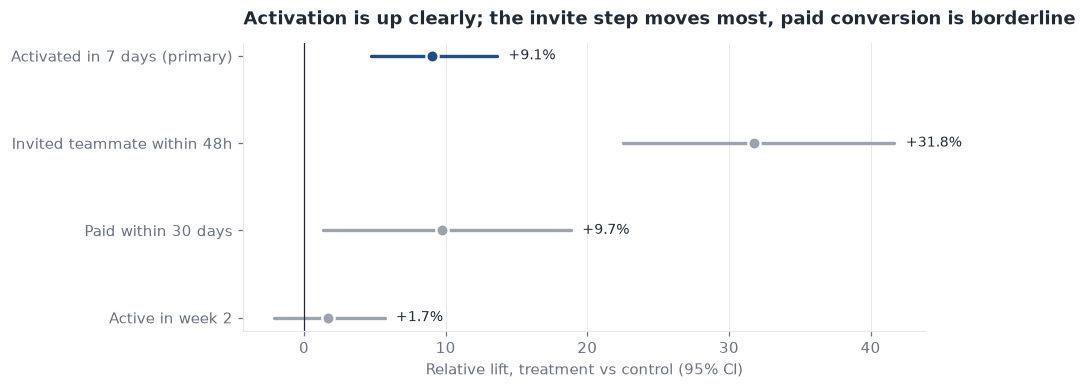

In [6]:
rows = [("Activated in 7 days (primary)", prim)] + [(labels[r["metric"]], r) for r in sec.to_dict("records")]
fig, ax = plt.subplots(figsize=(8, 3.4))
for i, (name, r) in enumerate(rows[::-1]):
    col = style.ACCENT if "primary" in name else style.GREY
    ax.plot([r["rel_lo"] * 100, r["rel_hi"] * 100], [i, i], color=col, lw=2.2, solid_capstyle="round")
    ax.plot(r["rel"] * 100, i, "o", color=col, ms=8, mec="white", mew=1.5)
    ax.text(r["rel_hi"] * 100 + 0.8, i, f"{r['rel']*100:+.1f}%", va="center", fontsize=9, color=style.INK)
ax.axvline(0, color=style.INK, lw=0.8)
ax.set_yticks(range(len(rows))); ax.set_yticklabels([r[0] for r in rows[::-1]])
ax.set_xlabel("Relative lift, treatment vs control (95% CI)"); ax.grid(axis="y", visible=False)
ax.set_title("Activation is up clearly; the invite step moves most, paid conversion is borderline")
style.save(fig, "exp_forest.png"); plt.show()

**A flaw in my own design:** support tickets are rare (about 0.04 per user), so a 17,000-user test can rule out a large increase but not a 10% one. The guardrail should have been sized in advance. I report it as **inconclusive** rather than loosening the limit after seeing the data, and the rollout plan monitors it.

**Reading this:** the primary metric has a tight interval well clear of zero, and the mechanism shows up where it should: the share of users who invite a teammate within 48 hours moves the most. Paid conversion moves in the right direction, but its interval is wide and it only just survives the multiple-comparison correction. Section 7 quantifies what the test could and could not detect.

## 5. Robustness: covariate-adjusted estimate

If randomisation worked, adjusting for pre-treatment attributes should barely change the estimate. It can tighten the interval.

In [7]:
m = smf.logit("activated ~ is_treat + C(acquisition_channel) + C(device) + C(company_size) + C(test_week)", df).fit(disp=0)
me = m.get_margeff(at="overall", dummy=True).summary_frame().loc["is_treat"]
print(f"Adjusted average effect: {me['dy/dx']*100:+.2f} pts (95% CI {me['Conf. Int. Low']*100:+.2f} to {me['Cont. Int. Hi.']*100:+.2f})  vs unadjusted {prim['diff']*100:+.2f}")
R["adjusted"] = dict(diff=me["dy/dx"], lo=me["Conf. Int. Low"], hi=me["Cont. Int. Hi."])

Adjusted average effect: +2.93 pts (95% CI +1.55 to +4.30)  vs unadjusted +2.96


## 6. Who benefits, and does the effect fade? (exploratory)

These cuts were not part of the primary hypothesis. Each segment has far fewer users than the whole test, so individual intervals are wide and some will look "interesting" by chance. The formal question is whether the effect differs **across** a dimension (interaction test), corrected for four dimensions looked at.

dimension,LR chi-square,df,p,p (Bonferroni x4)
company_size,1.826000,3,0.609000,1.000000
acquisition_channel,8.816000,6,0.184000,0.737000
device,2.880000,2,0.237000,0.948000
test_week,8.075000,5,0.152000,0.609000


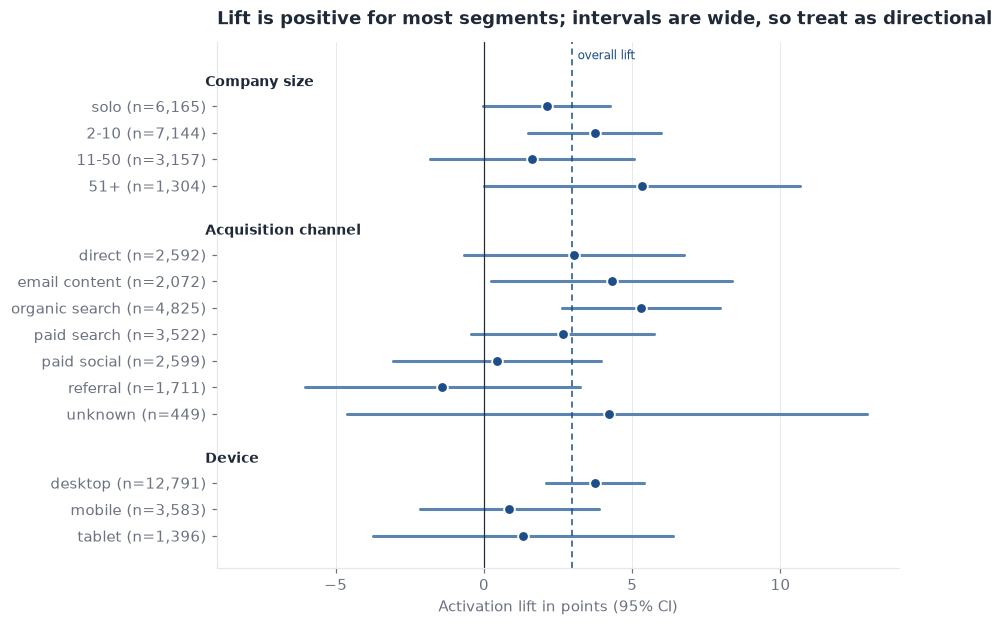

In [8]:
def seg_table(col, order=None):
    out = []
    for k, g in df.groupby(col):
        gc, gt = g[g.variant == "control"], g[g.variant == "treatment"]
        lo, hi = confint_proportions_2indep(gt.activated.sum(), len(gt), gc.activated.sum(), len(gc), method="newcomb")
        out.append(dict(dimension=col, segment=str(k), n=len(g), control=gc.activated.mean(), treatment=gt.activated.mean(),
                        diff=gt.activated.mean() - gc.activated.mean(), lo=lo, hi=hi))
    return pd.DataFrame(out)

def lr_interaction(col):
    m0 = smf.logit(f"activated ~ is_treat + C({col})", df).fit(disp=0)
    m1 = smf.logit(f"activated ~ is_treat * C({col})", df).fit(disp=0)
    lr = 2 * (m1.llf - m0.llf); dof = int(m1.df_model - m0.df_model)
    return lr, dof, stats.chi2.sf(lr, dof)

dims = ["company_size", "acquisition_channel", "device", "test_week"]
inter = pd.DataFrame([dict(dimension=d, **dict(zip(["LR chi-square", "df", "p"], lr_interaction(d)))) for d in dims])
inter["p (Bonferroni x4)"] = (inter.p * 4).clip(upper=1)
display(inter.round(3).style.hide(axis="index"))
R["interaction"] = inter.to_dict("records")

segs = pd.concat([seg_table(d) for d in ["company_size", "acquisition_channel", "device"]], ignore_index=True)
segs["segment"] = segs.segment.str.replace("_", " ")
order = {"company_size": ["solo", "2-10", "11-50", "51+"]}
fig, ax = plt.subplots(figsize=(8, 6.2))
y, ticks, names = 0, [], []
for d, label in [("company_size", "Company size"), ("acquisition_channel", "Acquisition channel"), ("device", "Device")]:
    sub = segs[segs.dimension == d]
    if d in order: sub = sub.set_index("segment").loc[order[d]].reset_index()
    ax.text(-9.4, y + 0.1, label, fontsize=9, fontweight="bold", color=style.INK, va="center", clip_on=False)
    y += 1
    for _, r in sub.iterrows():
        ax.plot([r.lo * 100, r.hi * 100], [y, y], color=style.ACCENT_MID, lw=2, solid_capstyle="round")
        ax.plot(r["diff"] * 100, y, "o", color=style.ACCENT, ms=7, mec="white", mew=1.2)
        ticks.append(y); names.append(f"{r.segment} (n={r.n:,})"); y += 1
    y += 0.6
ax.axvline(0, color=style.INK, lw=0.8)
ax.axvline(prim["diff"] * 100, color=style.ACCENT, lw=1, ls=(0, (4, 3)))
ax.text(prim["diff"] * 100 + 0.2, -0.9, "overall lift", color=style.ACCENT, fontsize=8, va="center")
ax.set_yticks(ticks); ax.set_yticklabels(names); ax.set_ylim(y - 0.4, -1.4); ax.grid(axis="y", visible=False)
ax.set_xlim(-9, 14); ax.set_xlabel("Activation lift in points (95% CI)")
ax.set_title("Lift is positive for most segments; intervals are wide, so treat as directional")
style.save(fig, "exp_segments.png"); plt.show()
R["segments"] = segs.to_dict("records")

week,n,control,treatment,diff,lo,hi
1,2933,32.340000,36.200000,3.860000,0.420000,7.280000
2,2881,31.720000,35.800000,4.090000,0.630000,7.520000
3,2739,33.090000,33.430000,0.340000,-3.190000,3.870000
4,3058,32.340000,37.570000,5.230000,1.850000,8.600000
5,3121,33.270000,33.180000,-0.090000,-3.390000,3.220000
6,3038,32.980000,37.150000,4.170000,0.780000,7.550000


Linear trend of the lift across test weeks: slope -0.81 log-odds x100 per week, p = 0.66


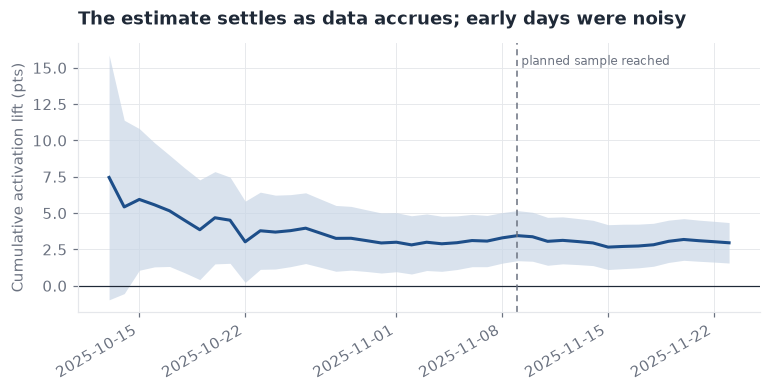

In [9]:
wk = seg_table("test_week")
wk["week"] = wk.segment.astype(int) + 1
mt = smf.logit("activated ~ is_treat * test_week", df).fit(disp=0)
p_trend = mt.pvalues["is_treat:test_week"]
display(wk[["week", "n", "control", "treatment", "diff", "lo", "hi"]].assign(**{c_: lambda d, c_=c_: (d[c_] * 100).round(2) for c_ in ["control", "treatment", "diff", "lo", "hi"]}).style.hide(axis="index"))
print(f"Linear trend of the lift across test weeks: slope {mt.params['is_treat:test_week']*100:+.2f} log-odds x100 per week, p = {p_trend:.2f}")

# cumulative lift as data accrued
dd = df.groupby(["signup_date", "variant"]).agg(n=("activated", "size"), x=("activated", "sum")).unstack(fill_value=0)
cum = dd.cumsum()
nc_, xc_, nt_, xt_ = cum[("n", "control")], cum[("x", "control")], cum[("n", "treatment")], cum[("x", "treatment")]
pc_, pt_ = xc_ / nc_, xt_ / nt_
se = np.sqrt(pc_ * (1 - pc_) / nc_ + pt_ * (1 - pt_) / nt_)
cl = pd.DataFrame({"diff": (pt_ - pc_) * 100, "lo": (pt_ - pc_ - 1.96 * se) * 100, "hi": (pt_ - pc_ + 1.96 * se) * 100})
reached = cum[("n", "control")].ge(n_arm) & cum[("n", "treatment")].ge(n_arm)
d_reach = reached.idxmax()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.fill_between(cl.index, cl.lo, cl.hi, color=style.ACCENT_LIGHT, alpha=0.7, lw=0)
ax.plot(cl.index, cl["diff"], color=style.ACCENT, lw=2)
ax.axhline(0, color=style.INK, lw=0.8); ax.axvline(d_reach, color=style.MUTED, lw=1, ls=(0, (4, 3)))
ax.text(d_reach, ax.get_ylim()[1] * 0.95, " planned sample reached", fontsize=8, color=style.MUTED, va="top")
ax.set_ylabel("Cumulative activation lift (pts)"); ax.set_title("The estimate settles as data accrues; early days were noisy")
fig.autofmt_xdate(); style.save(fig, "exp_cumulative.png"); plt.show()
R.update(weekly=wk.to_dict("records"), trend_p=p_trend, planned_sample_date=str(d_reach.date()))

**Interpretation:** the interaction tests ask whether the lift truly differs between groups. None of the segment differences should be read as a finding on their own; they are hypotheses for a follow-up test. The weekly estimates bounce around by more than the planned fade would explain, which is a reminder that a single week of data is too noisy to read a trend from.

## 7. Power and what the test could not tell us

A result of "not significant" only means something if the test could have detected a meaningful effect. Here is the power the test had for the primary and downstream metrics.

Smallest activation lift detectable with 80% power at n=8,797/arm: 2.00 pts (planned MDE 2.5)
Smallest paid-conversion lift detectable with 80% power: 1.38 pts; observed lift +1.11 pts
Power to detect a true +1.0 pt paid-conversion lift: 53%


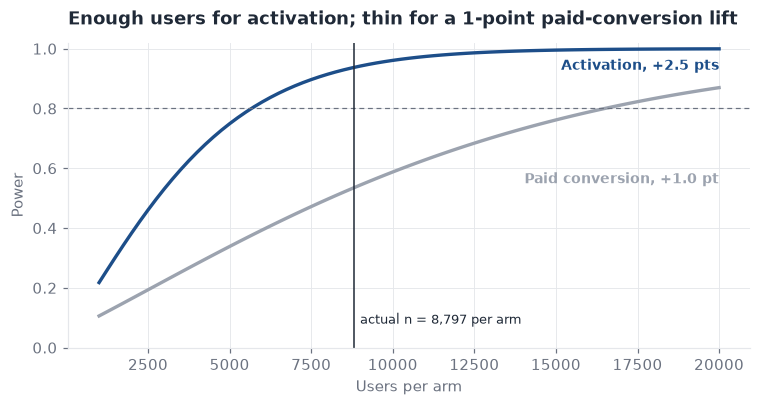

In [10]:
pw = NormalIndPower()
n_obs = min(len(c), len(t))
act_mde_80 = pw.solve_power(nobs1=n_obs, alpha=ALPHA, power=POWER, effect_size=None) # Cohen's h at 80% power
def mde_from_h(p0, hh):   # convert Cohen's h back to an absolute lift
    return np.sin((2 * np.arcsin(np.sqrt(p0)) + hh) / 2) ** 2 - p0
mde_act = mde_from_h(c.activated.mean(), act_mde_80)
mde_paid = mde_from_h(c.paid_30d.mean(), act_mde_80)
obs_paid = t.paid_30d.mean() - c.paid_30d.mean()
power_paid_1pt = pw.power(proportion_effectsize(c.paid_30d.mean() + 0.01, c.paid_30d.mean()), nobs1=n_obs, alpha=ALPHA)
print(f"Smallest activation lift detectable with 80% power at n={n_obs:,}/arm: {mde_act*100:.2f} pts (planned MDE {MDE*100:.1f})")
print(f"Smallest paid-conversion lift detectable with 80% power: {mde_paid*100:.2f} pts; observed lift {obs_paid*100:+.2f} pts")
print(f"Power to detect a true +1.0 pt paid-conversion lift: {power_paid_1pt:.0%}")
R.update(mde_activation_80=mde_act, mde_paid_80=mde_paid, power_paid_1pt=power_paid_1pt)

ns = np.arange(1000, 20001, 250)
fig, ax = plt.subplots(figsize=(8, 3.6))
for lab, p0, d_, colr in [("Activation, +2.5 pts", baseline, 0.025, style.ACCENT), ("Paid conversion, +1.0 pt", c.paid_30d.mean(), 0.01, style.GREY)]:
    ax.plot(ns, [pw.power(proportion_effectsize(p0 + d_, p0), nobs1=n, alpha=ALPHA) for n in ns], color=colr, lw=2.2)
    ax.text(ns[-1], (pw.power(proportion_effectsize(p0 + d_, p0), nobs1=ns[-1], alpha=ALPHA) - 0.07 if d_ > 0.02 else 0.55), lab, ha="right", color=colr, fontsize=9, fontweight="bold")
ax.axhline(0.8, color=style.MUTED, lw=0.8, ls=(0, (4, 3))); ax.axvline(n_obs, color=style.INK, lw=1)
ax.text(n_obs + 200, 0.08, f"actual n = {n_obs:,} per arm", fontsize=8.5)
ax.set_xlabel("Users per arm"); ax.set_ylabel("Power"); ax.set_ylim(0, 1.02)
ax.set_title("Enough users for activation; thin for a 1-point paid-conversion lift")
style.save(fig, "exp_power.png"); plt.show()

**Takeaway:** the test was sized for activation and answers that question decisively. The 30-day paid conversion result is borderline after correction and has a wide interval, so treat it as an encouraging estimate, not a confirmation: the test had only about even odds of detecting a true +1 point lift. This is why section 9 recommends a staged rollout with a long-term holdout rather than a one-shot switch.

## 8. Business impact

Translate the lift into new recurring revenue. All inputs come from the data except two flagged assumptions.

In [11]:
mrr_t, mrr_c = t.mrr_30d, c.mrr_30d
d_mrr = mrr_t.mean() - mrr_c.mean()
se_mrr = np.sqrt(mrr_t.var(ddof=1) / len(t) + mrr_c.var(ddof=1) / len(c))
mrr_lo, mrr_hi = d_mrr - 1.96 * se_mrr, d_mrr + 1.96 * se_mrr

q4 = trend[trend.signup_month >= "2025-10-01"]
signups_pm = pd.read_csv(ROOT / "outputs" / "funnel_monthly_trend.csv").query("signup_month >= '2025-10-01'").signups.mean()
extra_act = prim["diff"] * signups_pm
print(f"Monthly signups (Oct-Dec 2025 average): {signups_pm:,.0f}")
print(f"Extra activated users per month at full rollout: {extra_act:,.0f}  (CI {prim['ci_lo']*signups_pm:,.0f} to {prim['ci_hi']*signups_pm:,.0f})")
print(f"New MRR per signup (30-day): control ${mrr_c.mean():.2f}, treatment ${mrr_t.mean():.2f}; diff ${d_mrr:+.2f} (CI {mrr_lo:+.2f} to {mrr_hi:+.2f})")
print(f"Implied extra new MRR per month: ${d_mrr*signups_pm:,.0f}  (CI {mrr_lo*signups_pm:,.0f} to {mrr_hi*signups_pm:,.0f})")

# value of an extra activated user, from the whole base (not only the test)
gap = pd.read_csv(ROOT / "outputs" / "activation_to_paid_gap.csv").set_index("segment")
uplift_paid = (gap.loc["Activated", "paid_pct"] - gap.loc["Not activated", "paid_pct"]) / 100
mrr_per_new = gap.loc["Activated", "avg_mrr_usd"]
bar = 0.01 * signups_pm * uplift_paid * mrr_per_new
print(f"Break-even reference: a +1.0 pt activation lift is worth about ${bar:,.0f} new MRR per month "
      f"(extra activated users x {uplift_paid:.0%} paid uplift x ${mrr_per_new:.0f} MRR). This is the basis for the 1.0 pt practical bar.")
R["impact"] = dict(signups_pm=signups_pm, extra_activated_pm=extra_act, extra_act_lo=prim["ci_lo"]*signups_pm, extra_act_hi=prim["ci_hi"]*signups_pm,
                   d_mrr_per_signup=d_mrr, d_mrr_lo=mrr_lo, d_mrr_hi=mrr_hi, extra_mrr_pm=d_mrr*signups_pm,
                   extra_mrr_pm_lo=mrr_lo*signups_pm, extra_mrr_pm_hi=mrr_hi*signups_pm, one_pt_value_mrr_pm=bar)

Monthly signups (Oct-Dec 2025 average): 13,411
Extra activated users per month at full rollout: 397  (CI 210 to 584)
New MRR per signup (30-day): control $9.59, treatment $10.60; diff $+1.01 (CI +0.01 to +2.02)
Implied extra new MRR per month: $13,604  (CI 129 to 27,079)
Break-even reference: a +1.0 pt activation lift is worth about $2,972 new MRR per month (extra activated users x 27% paid uplift x $83 MRR). This is the basis for the 1.0 pt practical bar.


**Assumptions to confirm with Finance and Product:** (1) the 1.0 point practical bar reflects the real build and upkeep cost of the checklist, which is not in this dataset; (2) the lift persists at full rollout. Revenue figures are new MRR booked before churn, not lifetime value.

## 9. Decision

In [12]:
p_ = prim
sp = sec.set_index("metric").loc["paid_30d"]

def status(point_ok, bound_ok):
    return "Met" if bound_ok else ("Inconclusive" if point_ok else "Not met")

tests = [
    ("Primary: activation lift is statistically significant (p < 0.05)", status(p_["diff"] > 0, p_["p"] < ALPHA), f"p = {p_['p']:.2g}"),
    ("Primary: lift clears the 1.0 pt practical bar (CI lower bound > +1.0 pt)", status(p_["diff"] > 0.01, p_["ci_lo"] > 0.01), f"point {p_['diff']*100:+.2f}, CI lower bound {p_['ci_lo']*100:+.2f} pts"),
    ("Guardrail: support tickets rise by less than 10% (CI upper bound < 1.10)", status(rr < 1.10, rr_hi < 1.10), f"rate ratio {rr:.2f}, CI upper bound {rr_hi:.2f}"),
    ("Guardrail: week-2 activity does not fall more than 1 pt", status(w1["diff"] > -0.01, w1.ci_lo > -0.01), f"difference {w1['diff']*100:+.2f} pts, CI lower bound {w1.ci_lo*100:+.2f}"),
    ("Downstream: paid conversion shows no sign of harm (CI lower bound > -0.5 pt)", status(sp["diff"] > -0.005, sp.ci_lo > -0.005), f"difference {sp['diff']*100:+.2f} pts, CI lower bound {sp.ci_lo*100:+.2f}"),
]
tbl = pd.DataFrame(tests, columns=["Pre-registered criterion", "Status", "Evidence"])
display(tbl.style.hide(axis="index"))
states = [x[1] for x in tests]
if "Not met" in states:
    verdict, ship = "DO NOT SHIP", False
elif "Inconclusive" in states:
    verdict, ship = "SHIP VIA STAGED ROLLOUT, monitoring the inconclusive guardrail", True
else:
    verdict, ship = "SHIP", True
R["criteria"] = [dict(criterion=a, status=b, evidence=c_) for a, b, c_ in tests]
R["ship"] = bool(ship); R["verdict"] = verdict
display(Markdown(f"### Recommendation: {verdict}"))

def clean(o):
    if isinstance(o, dict): return {k: clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    return o
(ROOT / "outputs" / "exp_results.json").write_text(json.dumps(clean(R), indent=2, default=str))

Pre-registered criterion,Status,Evidence
Primary: activation lift is statistically significant (p < 0.05),Met,p = 3.2e-05
Primary: lift clears the 1.0 pt practical bar (CI lower bound > +1.0 pt),Met,"point +2.96, CI lower bound +1.57 pts"
Guardrail: support tickets rise by less than 10% (CI upper bound < 1.10),Inconclusive,"rate ratio 0.98, CI upper bound 1.14"
Guardrail: week-2 activity does not fall more than 1 pt,Met,"difference +0.64 pts, CI lower bound -0.79"
Downstream: paid conversion shows no sign of harm (CI lower bound > -0.5 pt),Met,"difference +1.11 pts, CI lower bound +0.16"


### Recommendation: SHIP VIA STAGED ROLLOUT, monitoring the inconclusive guardrail

10265

### What would change this recommendation
- A real build and maintenance cost well above the break-even value in section 8 (the practical bar would need to rise).
- A drop in 90-day retention or a rise in churn in the holdout group once those outcomes mature. They could not be observed inside the test window.
- Evidence that the effect is concentrated in segments we plan to deprioritise, from the follow-up test on company size and channel.

### Limitations
- Simulated data: real traffic would add bot signups, multiple devices per person and tracking gaps.
- Only 30 days of paid-conversion follow-up; churn and long-run retention are not measured for these users.
- Segment results are exploratory and individually under-powered.
- One test, one market. Seasonality (Q4 buying cycles) may not transfer to other quarters.